# Part C — Reproducing Paper Calculations

In this part, I implement four reinforcement learning methods:
Model-Based Learning, Monte Carlo, TD(0), and Q-learning.

I use the four given Blackjack games from Part B.
My goal is to reproduce my handwritten calculations
and compare the results with Python.

In [1]:
import pandas as pd
from google.colab import files
from IPython.display import display

# Upload the original HW7 ZIP file
uploaded = files.upload()

# Extract the ZIP archive
import zipfile
import io

zip_name = next(name for name in uploaded if name.endswith(".zip"))

with zipfile.ZipFile(io.BytesIO(uploaded[zip_name])) as archive:
    games_file = next(
        name for name in archive.namelist()
        if name.endswith("data/paper-games.csv")
    )
    states_file = next(
        name for name in archive.namelist()
        if name.endswith("data/states.csv")
    )

    games = pd.read_csv(archive.open(games_file))
    states = pd.read_csv(archive.open(states_file))

print("Given Blackjack games:")
display(games)

print("State information:")
display(states)

Saving css4007-hw7-main.zip to css4007-hw7-main.zip
Given Blackjack games:


,game,step,state,action,next_state,reward,terminated
0,1,1,A,1,B,0,False
1,1,2,B,0,END,1,True
2,2,1,A,1,END,-1,True
3,3,1,C,1,D,0,False
4,3,2,D,1,E,0,False
5,3,3,E,0,END,0,True
6,4,1,A,1,B,0,False
7,4,2,B,0,END,-1,True


State information:


,label,player_sum,dealer_showing,usable_ace
0,A,18,6,0
1,B,20,6,0
2,C,17,6,1
3,D,17,6,0
4,E,21,6,0


## C.1 — Model-Based Learning

In this method, I learn from observed game transitions.

First, I count how many times each transition happened.
Then, I estimate transition probabilities and mean rewards.

Finally, I evaluate the fixed policy using two synchronous sweeps.

I use gamma = 1 and initialize all state values to zero.

In [2]:
from collections import defaultdict, Counter
import pandas as pd

# Step 1: Count transitions and collect rewards
counts = defaultdict(Counter)
rewards = defaultdict(list)

for row in games.itertuples(index=False):
    key = (row.state, int(row.action))
    next_state = row.next_state

    counts[key][next_state] += 1
    rewards[(row.state, int(row.action), next_state)].append(
        float(row.reward)
    )

# Step 2: Estimate probabilities and mean rewards
model_rows = []

for (state, action), next_counts in counts.items():
    total = sum(next_counts.values())

    for next_state, count in next_counts.items():
        probability = count / total
        mean_reward = sum(
            rewards[(state, action, next_state)]
        ) / count

        model_rows.append({
            "State": state,
            "Action": "Hit" if action == 1 else "Stick",
            "Next": next_state,
            "Count": count,
            "Probability": probability,
            "Mean reward": mean_reward
        })

model_df = pd.DataFrame(model_rows)

print("Learned transition model:")
display(model_df.round(4))

Learned transition model:


,State,Action,Next,Count,Probability,Mean reward
0,A,Hit,B,2,0.6667,0.0
1,A,Hit,END,1,0.3333,-1.0
2,B,Stick,END,2,1.0000,0.0
3,C,Hit,D,1,1.0000,0.0
4,D,Hit,E,1,1.0000,0.0
5,E,Stick,END,1,1.0000,0.0


In [3]:
# Fixed policy: hit below 20, otherwise stick
policy = {
    row.label: 1 if row.player_sum < 20 else 0
    for row in states.itertuples(index=False)
}

gamma = 1.0
V = {state: 0.0 for state in states["label"]}
history = [{"Sweep": 0, **V}]

# Two synchronous policy-evaluation sweeps
for sweep in range(1, 3):
    old_V = V.copy()
    new_V = {}

    for state in states["label"]:
        action = policy[state]
        outcomes = counts.get((state, action))

        if not outcomes:
            new_V[state] = None  # Unobserved pair
            continue

        total = sum(outcomes.values())
        value = 0.0

        for next_state, count in outcomes.items():
            p = count / total
            r = sum(
                rewards[(state, action, next_state)]
            ) / count

            next_value = (
                0.0 if next_state == "END"
                else old_V[next_state]
            )

            value += p * (r + gamma * next_value)

        new_V[state] = value

    V = new_V
    history.append({"Sweep": sweep, **V})

print("Two synchronous sweeps:")
value_df = pd.DataFrame(history)
display(value_df.round(4))

# Compare with handwritten results
paper = {"A": -1/3, "B": 0, "C": 0, "D": 0, "E": 0}

comparison = pd.DataFrame([
    {
        "State": state,
        "Paper": paper[state],
        "Python": V[state],
        "Difference": V[state] - paper[state]
    }
    for state in states["label"]
])

print("Paper vs Python:")
display(comparison.round(6))

Two synchronous sweeps:


,Sweep,A,B,C,D,E
0,0,0.0000,0.0,0.0,0.0,0.0
1,1,-0.3333,0.0,0.0,0.0,0.0
2,2,-0.3333,0.0,0.0,0.0,0.0


Paper vs Python:


,State,Paper,Python,Difference
0,A,-0.333333,-0.333333,0.0
1,B,0.000000,0.000000,0.0
2,C,0.000000,0.000000,0.0
3,D,0.000000,0.000000,0.0
4,E,0.000000,0.000000,0.0


### Conclusion

I estimated transition probabilities and rewards from four games.

I performed two synchronous policy-evaluation sweeps.

The final value of state A is -0.3333.
All other state values are zero.

My Python results match my paper calculations.
These are sample estimates, not true game probabilities.

## C.2 — Direct Evaluation (Monte Carlo)

I use every-visit Monte Carlo to estimate state values.

First, I calculate the total return from each state visit until the end of the game.

Then, I average the returns for each state.

I process all four games once and compare the results with my handwritten calculations.

In [4]:
# C.2 — Every-Visit Monte Carlo

import pandas as pd

gamma = 1.0
visit_rows = []

# Process all four games once
for game_id, episode in games.sort_values(
    ["game", "step"]
).groupby("game"):

    G = 0.0

    # Calculate returns backwards
    for _, row in episode.iloc[::-1].iterrows():
        G = float(row["reward"]) + gamma * G

        visit_rows.append({
            "Game": game_id,
            "Step": row["step"],
            "State": row["state"],
            "Return": G
        })

visits_df = pd.DataFrame(visit_rows)
visits_df = visits_df.sort_values(["Game", "Step"])

print("Returns from every state visit:")
display(visits_df)

# Average returns for every state
mc_rows = []

for state in states["label"]:
    returns = visits_df.loc[
        visits_df["State"] == state, "Return"
    ].tolist()

    mc_rows.append({
        "State": state,
        "Returns": str(returns),
        "Visits": len(returns),
        "MC Value": sum(returns) / len(returns)
        if returns else float("nan")
    })

mc_df = pd.DataFrame(mc_rows)

print("Monte Carlo results:")
display(mc_df.round(4))

# Compare with paper calculations
paper_mc = {
    "A": -1/3,
    "B": 0.0,
    "C": 0.0,
    "D": 0.0,
    "E": 0.0
}

comparison_mc = mc_df[["State", "MC Value"]].copy()
comparison_mc["Method"] = "Monte Carlo"
comparison_mc["Pass"] = 1
comparison_mc["Paper"] = comparison_mc["State"].map(paper_mc)
comparison_mc["Difference"] = (
    comparison_mc["MC Value"] - comparison_mc["Paper"]
)

print("Paper vs Python:")
display(comparison_mc.round(6))

Returns from every state visit:


,Game,Step,State,Return
1,1,1,A,1.0
0,1,2,B,1.0
2,2,1,A,-1.0
5,3,1,C,0.0
4,3,2,D,0.0
3,3,3,E,0.0
7,4,1,A,-1.0
6,4,2,B,-1.0


Monte Carlo results:


,State,Returns,Visits,MC Value
0,A,"[1.0, -1.0, -1.0]",3,-0.3333
1,B,"[1.0, -1.0]",2,0.0000
2,C,[0.0],1,0.0000
3,D,[0.0],1,0.0000
4,E,[0.0],1,0.0000


Paper vs Python:


,State,MC Value,Method,Pass,Paper,Difference
0,A,-0.333333,Monte Carlo,1,-0.333333,0.0
1,B,0.000000,Monte Carlo,1,0.000000,0.0
2,C,0.000000,Monte Carlo,1,0.000000,0.0
3,D,0.000000,Monte Carlo,1,0.000000,0.0
4,E,0.000000,Monte Carlo,1,0.000000,0.0


### Conclusion

I used every-visit Monte Carlo to estimate state values.

State A has three returns: +1, -1, and -1.
Its average value is -0.3333.

All other state values are zero.

My Python results match my paper calculations.

## C.3 — TD(0) Learning

TD(0) updates state values after each transition.

I use a learning rate of 0.1 and gamma = 1.

I process the four games twice without resetting the values.

After each update, I compare the Python result with my paper calculation.

In [5]:
# C.3 — TD(0)

import pandas as pd

alpha = 0.1
gamma = 1.0

# Start with fresh zero values
V_td = {s: 0.0 for s in states["label"]}

# Results from my handwritten Part B
paper_td = [
    [0, 0.1, -0.1, 0, 0, 0, -0.08, -0.01],
    [-0.073, 0.091, -0.1657, 0, 0, 0,
     -0.14003, -0.0181]
]

td_rows = []
ordered_games = games.sort_values(["game", "step"])

# Replay the same games twice
for pass_num in [1, 2]:

    for i, row in enumerate(
        ordered_games.itertuples(index=False)
    ):
        s = row.state
        next_s = row.next_state
        r = float(row.reward)

        old = V_td[s]

        # Terminal state has value zero
        next_value = (
            0.0 if next_s == "END"
            else V_td[next_s]
        )

        # TD(0) formula
        target = r + gamma * next_value
        new = old + alpha * (target - old)

        # Update immediately
        V_td[s] = new

        paper = paper_td[pass_num - 1][i]

        td_rows.append({
            "Method": "TD(0)",
            "Pass": pass_num,
            "Game": row.game,
            "Step": row.step,
            "State": s,
            "Old": old,
            "Reward": r,
            "Next V": next_value,
            "Target": target,
            "New V": new,
            "Paper": paper,
            "Difference": new - paper
        })

td_df = pd.DataFrame(td_rows)

print("Every TD(0) update:")
display(td_df.round(5))

print("Final TD(0) values:")
final_td = pd.DataFrame([
    {"State": s, "Value": V_td[s]}
    for s in states["label"]
])
display(final_td.round(5))

print("Maximum difference:")
print(round(td_df["Difference"].abs().max(), 8))

Every TD(0) update:


,Method,Pass,Game,Step,State,Old,Reward,Next V,Target,New V,Paper,Difference
0,TD(0),1,1,1,A,0.0000,0.0,0.000,0.000,0.00000,0.00000,0.0
1,TD(0),1,1,2,B,0.0000,1.0,0.000,1.000,0.10000,0.10000,0.0
2,TD(0),1,2,1,A,0.0000,-1.0,0.000,-1.000,-0.10000,-0.10000,0.0
3,TD(0),1,3,1,C,0.0000,0.0,0.000,0.000,0.00000,0.00000,0.0
4,TD(0),1,3,2,D,0.0000,0.0,0.000,0.000,0.00000,0.00000,0.0
5,TD(0),1,3,3,E,0.0000,0.0,0.000,0.000,0.00000,0.00000,0.0
6,TD(0),1,4,1,A,-0.1000,0.0,0.100,0.100,-0.08000,-0.08000,0.0
7,TD(0),1,4,2,B,0.1000,-1.0,0.000,-1.000,-0.01000,-0.01000,-0.0
8,TD(0),2,1,1,A,-0.0800,0.0,-0.010,-0.010,-0.07300,-0.07300,-0.0
9,TD(0),2,1,2,B,-0.0100,1.0,0.000,1.000,0.09100,0.09100,0.0


Final TD(0) values:


,State,Value
0,A,-0.14003
1,B,-0.01810
2,C,0.00000
3,D,0.00000
4,E,0.00000


Maximum difference:
0.0


### Conclusion

I implemented TD(0) with alpha = 0.1 and gamma = 1.

I updated state values after every transition.
I repeated the four games twice without resetting.

The final values are:
A = -0.14003 and B = -0.0181.
Other state values are zero.

My Python results match my paper calculations.

## C.4 — Q-learning

I use Q-learning to estimate action values.

Unlike TD(0), Q-learning estimates Q(s, a)
instead of only V(s).

I use alpha = 0.1 and gamma = 1.

I process all four games twice without resetting
the Q-table. Then I compare the results with
my handwritten calculations.

In [6]:
# C.4 — Q-learning

import pandas as pd

alpha = 0.1
gamma = 1.0

# 0 = Stick, 1 = Hit
actions = [0, 1]

# Initialize all Q-values to zero
Q = {
    (s, a): 0.0
    for s in states["label"]
    for a in actions
}

# Handwritten Part B results
paper_q = [
    [0, 0.1, -0.1, 0, 0, 0, -0.08, -0.01],
    [-0.072, 0.091, -0.1648, 0, 0, 0,
     -0.13922, -0.0181]
]

q_rows = []
ordered_games = games.sort_values(["game", "step"])

# Two passes without resetting
for pass_num in [1, 2]:

    for i, row in enumerate(
        ordered_games.itertuples(index=False)
    ):
        s = row.state
        a = int(row.action)
        next_s = row.next_state
        r = float(row.reward)

        old_q = Q[(s, a)]

        # Find the best action value in next state
        if next_s == "END":
            max_next_q = 0.0
        else:
            max_next_q = max(
                Q[(next_s, next_a)]
                for next_a in actions
            )

        # Q-learning update
        target = r + gamma * max_next_q
        new_q = old_q + alpha * (target - old_q)

        Q[(s, a)] = new_q

        paper = paper_q[pass_num - 1][i]

        q_rows.append({
            "Pass": pass_num,
            "Game": row.game,
            "Step": row.step,
            "State": s,
            "Action": "Hit" if a == 1 else "Stick",
            "Old Q": old_q,
            "Reward": r,
            "Max next Q": max_next_q,
            "Target": target,
            "New Q": new_q,
            "Paper": paper,
            "Difference": new_q - paper
        })

q_df = pd.DataFrame(q_rows)

print("Q-learning updates:")
display(q_df.round(5))

# Final Q-table and greedy actions
final_q_rows = []

for s in states["label"]:
    hit = Q[(s, 1)]
    stick = Q[(s, 0)]

    if hit == stick:
        best = "Tie"
    elif hit > stick:
        best = "Hit"
    else:
        best = "Stick"

    final_q_rows.append({
        "State": s,
        "Hit": hit,
        "Stick": stick,
        "Greedy action": best
    })

final_q = pd.DataFrame(final_q_rows)

print("Final Q-table:")
display(final_q.round(5))

print("Maximum difference:")
print(round(q_df["Difference"].abs().max(), 8))

Q-learning updates:


,Pass,Game,Step,State,Action,Old Q,Reward,Max next Q,Target,New Q,Paper,Difference
0,1,1,1,A,Hit,0.0000,0.0,0.000,0.000,0.00000,0.00000,0.0
1,1,1,2,B,Stick,0.0000,1.0,0.000,1.000,0.10000,0.10000,0.0
2,1,2,1,A,Hit,0.0000,-1.0,0.000,-1.000,-0.10000,-0.10000,0.0
3,1,3,1,C,Hit,0.0000,0.0,0.000,0.000,0.00000,0.00000,0.0
4,1,3,2,D,Hit,0.0000,0.0,0.000,0.000,0.00000,0.00000,0.0
5,1,3,3,E,Stick,0.0000,0.0,0.000,0.000,0.00000,0.00000,0.0
6,1,4,1,A,Hit,-0.1000,0.0,0.100,0.100,-0.08000,-0.08000,0.0
7,1,4,2,B,Stick,0.1000,-1.0,0.000,-1.000,-0.01000,-0.01000,-0.0
8,2,1,1,A,Hit,-0.0800,0.0,0.000,0.000,-0.07200,-0.07200,-0.0
9,2,1,2,B,Stick,-0.0100,1.0,0.000,1.000,0.09100,0.09100,0.0


Final Q-table:


,State,Hit,Stick,Greedy action
0,A,-0.13922,0.0000,Stick
1,B,0.00000,-0.0181,Hit
2,C,0.00000,0.0000,Tie
3,D,0.00000,0.0000,Tie
4,E,0.00000,0.0000,Tie


Maximum difference:
0.0


### Conclusion

I implemented Q-learning with alpha = 0.1
and gamma = 1.

I processed four games twice.

The final Q(A, Hit) is -0.13922.
The final Q(B, Stick) is -0.0181.

My Python results match my handwritten calculations.

The greedy policy is based on estimated Q-values.
An unvisited action with value zero is not
necessarily a good action.

# Part D — Learning from Simulated Blackjack Games

## D.1 — Data Collection

I use Gymnasium Blackjack-v1 to simulate games.

I follow a fixed policy:
- Hit when the player has less than 20.
- Stick when the player has 20 or 21.

I collect 10,000 games for each seed: 11, 22, and 33.

I save all transitions to use the same data for
Model-Based Learning, Monte Carlo, and TD(0).

In [7]:
!pip -q install gymnasium

import gymnasium as gym
import pandas as pd
import os
from importlib.metadata import version

print("Gymnasium version:", version("gymnasium"))

os.makedirs("outputs/fixed-policy", exist_ok=True)

all_summaries = []

for seed in [11, 22, 33]:

    env = gym.make(
        "Blackjack-v1",
        natural=False,
        sab=False
    )

    records = []
    wins = losses = draws = cutoffs = 0

    for game in range(1, 10001):

        # Seed only the first reset
        if game == 1:
            obs, _ = env.reset(seed=seed)
        else:
            obs, _ = env.reset()

        for step in range(1, 101):

            # Fixed policy
            action = 1 if obs[0] < 20 else 0

            next_obs, reward, terminated, truncated, _ = (
                env.step(action)
            )

            done = terminated or truncated
            cutoff = truncated or (step == 100 and not done)

            records.append({
                "seed": seed,
                "game": game,
                "step": step,
                "observation": str(tuple(obs)),
                "action": action,
                "reward": reward,
                "next_observation": (
                    "END" if done
                    else "CUT_OFF" if cutoff
                    else str(tuple(next_obs))
                ),
                "terminal": terminated,
                "cutoff": cutoff
            })

            if cutoff:
                cutoffs += 1
                break

            if terminated:
                if reward == 1:
                    wins += 1
                elif reward == -1:
                    losses += 1
                else:
                    draws += 1
                break

            obs = next_obs

    env.close()

    # Save the full game history
    df = pd.DataFrame(records)
    df.to_csv(
        f"outputs/fixed-policy/games_seed_{seed}.csv",
        index=False
    )

    all_summaries.append({
        "Seed": seed,
        "Games": 10000,
        "Wins": wins,
        "Losses": losses,
        "Draws": draws,
        "Cut-offs": cutoffs,
        "Transitions": len(df)
    })

summary_df = pd.DataFrame(all_summaries)
summary_df.to_csv(
    "outputs/fixed-policy/summary.csv",
    index=False
)

print("Fixed-policy data collection:")
display(summary_df)

Gymnasium version: 1.4.0
Fixed-policy data collection:


,Seed,Games,Wins,Losses,Draws,Cut-offs,Transitions
0,11,10000,2991,6415,594,0,17958
1,22,10000,2940,6447,613,0,18036
2,33,10000,2904,6489,607,0,17912


## D.2 — Model-Based Policy Evaluation

I use the saved Blackjack games to learn a transition model.

First, I count transitions and estimate their probabilities and mean rewards.

Then, I evaluate the fixed policy using synchronous Bellman updates.

I repeat this after 100, 1,000, and 10,000 games for each seed.

I stop when the maximum value change is below 0.000001.
Missing observations are not treated as learned zero values.

In [8]:
# D.2 — Model-Based Policy Evaluation

import pandas as pd
import numpy as np
import ast
import os
from collections import defaultdict, Counter

os.makedirs("outputs/model-based", exist_ok=True)

seeds = [11, 22, 33]
checkpoints = [100, 1000, 10000]
tol = 1e-6
max_sweeps = 10000

def parse_state(text):
    if text in ("END", "CUT_OFF"):
        return text
    return ast.literal_eval(text)

def evaluate_model(data):
    # Count visits and observed transitions
    visits = Counter()
    transitions = defaultdict(
        lambda: defaultdict(lambda: [0, 0.0])
    )

    for row in data.itertuples(index=False):
        s = parse_state(row.observation)
        ns = parse_state(row.next_observation)
        a = int(row.action)
        r = float(row.reward)

        assert a == (1 if s[0] < 20 else 0)

        visits[s] += 1
        transitions[s][ns][0] += 1
        transitions[s][ns][1] += r

    # Identify missing successor information
    missing = {
        ns
        for outcomes in transitions.values()
        for ns in outcomes
        if ns != "END" and ns not in visits
    }

    affected = set()
    for s, outcomes in transitions.items():
        if any(ns in missing for ns in outcomes):
            affected.add(s)

    # Propagate missing information backwards
    changed = True
    while changed:
        changed = False
        for s, outcomes in transitions.items():
            if s not in affected and any(
                ns in affected for ns in outcomes
            ):
                affected.add(s)
                changed = True

    valid_states = [s for s in visits if s not in affected]

    # Start value estimates from zero
    V = {s: 0.0 for s in valid_states}
    converged = False
    sweeps = 0
    delta = np.nan

    # Synchronous Bellman evaluation
    for sweep in range(1, max_sweeps + 1):
        old_V = V.copy()
        new_V = {}

        for s in valid_states:
            value = 0.0

            for ns, (count, reward_sum) in transitions[s].items():
                p = count / visits[s]
                mean_reward = reward_sum / count

                next_value = (
                    0.0 if ns == "END"
                    else old_V[ns]
                )

                value += p * (mean_reward + next_value)

            new_V[s] = value

        delta = max(
            (abs(new_V[s] - old_V[s]) for s in valid_states),
            default=0.0
        )
        V = new_V
        sweeps = sweep

        if delta < tol:
            converged = True
            break

    # Save the learned transition model
    model_rows = []
    for s, outcomes in transitions.items():
        for ns, (count, reward_sum) in outcomes.items():
            model_rows.append({
                "State": str(s),
                "Action": "Hit" if s[0] < 20 else "Stick",
                "Next state": str(ns),
                "Count": count,
                "Probability": count / visits[s],
                "Mean reward": reward_sum / count
            })

    # Build full state tables
    value_rows = []

    for ace in [False, True]:
        for player_sum in range(4, 22):
            for dealer in range(1, 11):
                s = (player_sum, dealer, ace)
                count = visits[s]

                if count == 0:
                    status = "Unobserved"
                elif s in affected:
                    status = "Missing successor"
                else:
                    status = "Estimated"

                value_rows.append({
                    "Player sum": player_sum,
                    "Dealer card": dealer,
                    "Usable ace": ace,
                    "Visits": count,
                    "Value": V.get(s, np.nan),
                    "Status": status
                })

    return (
        pd.DataFrame(value_rows),
        pd.DataFrame(model_rows),
        {
            "Observed states": len(visits),
            "Affected states": len(affected),
            "Missing successors": len(missing),
            "Sweeps": sweeps,
            "Converged": converged,
            "Final delta": delta
        }
    )

summaries = []
all_results = {}

for seed in seeds:
    data = pd.read_csv(
        f"outputs/fixed-policy/games_seed_{seed}.csv"
    )

    if data["cutoff"].any():
        raise ValueError("Unexpected cut-off: investigate first")

    for checkpoint in checkpoints:
        subset = data[data["game"] <= checkpoint]

        values, model, info = evaluate_model(subset)

        values.to_csv(
            f"outputs/model-based/values_{seed}_{checkpoint}.csv",
            index=False
        )
        model.to_csv(
            f"outputs/model-based/model_{seed}_{checkpoint}.csv",
            index=False
        )

        all_results[(seed, checkpoint)] = values

        summaries.append({
            "Seed": seed,
            "Games": checkpoint,
            **info
        })

summary_model = pd.DataFrame(summaries)
summary_model.to_csv(
    "outputs/model-based/summary.csv",
    index=False
)

print("Model-Based Evaluation Summary:")
display(summary_model.round(7))

print("Saved all model-based results.")

Model-Based Evaluation Summary:


,Seed,Games,Observed states,Affected states,Missing successors,Sweeps,Converged,Final delta
0,11,100,96,0,0,6,True,0.000000e+00
1,11,1000,243,0,0,12,True,0.000000e+00
2,11,10000,280,0,0,11,True,3.000000e-07
3,22,100,116,0,0,6,True,0.000000e+00
4,22,1000,245,0,0,10,True,5.000000e-07
5,22,10000,280,0,0,11,True,1.000000e-07
6,33,100,118,0,0,5,True,0.000000e+00
7,33,1000,247,0,0,11,True,1.000000e-07
8,33,10000,280,0,0,11,True,2.000000e-07


Saved all model-based results.


In [9]:
# Display state-value tables for seed 11
# after 10,000 games

results = all_results[(11, 10000)]

for ace in [False, True]:

    subset = results[
        results["Usable ace"] == ace
    ]

    print("\nUsable ace:", ace)

    # State values
    value_table = subset.pivot(
        index="Player sum",
        columns="Dealer card",
        values="Value"
    )

    print("Estimated state values:")
    display(value_table.round(3))

    # Visit counts
    count_table = subset.pivot(
        index="Player sum",
        columns="Dealer card",
        values="Visits"
    )

    print("Visit counts:")
    display(count_table)


Usable ace: False
Estimated state values:


Dealer card,1,2,3,4,5,6,7,8,9,10
Player sum,,,,,,,,,,
4,-0.698,-0.569,-0.252,-0.367,-0.554,-0.693,-0.146,-0.605,-0.488,-0.524
5,-0.630,-0.491,-0.422,-0.530,-0.381,-0.486,-0.472,-0.485,-0.395,-0.530
6,-0.655,-0.594,-0.534,-0.489,-0.349,-0.601,-0.410,-0.456,-0.439,-0.546
7,-0.649,-0.532,-0.498,-0.413,-0.526,-0.534,-0.243,-0.549,-0.464,-0.518
8,-0.620,-0.624,-0.601,-0.488,-0.460,-0.486,-0.490,-0.622,-0.573,-0.542
9,-0.538,-0.660,-0.508,-0.424,-0.439,-0.453,-0.327,-0.623,-0.519,-0.573
10,-0.285,-0.144,-0.202,-0.153,-0.034,-0.031,-0.031,-0.282,-0.146,-0.194
11,-0.121,-0.055,-0.132,-0.021,-0.036,-0.125,0.005,-0.094,0.077,-0.118
12,-0.658,-0.584,-0.457,-0.666,-0.617,-0.598,-0.516,-0.681,-0.591,-0.564


Visit counts:


Dealer card,1,2,3,4,5,6,7,8,9,10
Player sum,,,,,,,,,,
4,2,5,2,3,2,1,4,5,1,13
5,10,9,9,12,10,12,13,14,10,38
6,13,13,15,20,16,12,13,19,11,35
7,24,14,21,17,27,29,24,28,17,76
8,23,27,29,24,23,27,16,28,32,80
9,27,27,37,33,30,28,30,29,40,112
10,38,38,28,32,45,42,44,42,46,129
11,38,48,49,51,45,51,57,46,49,175
12,94,104,91,83,87,94,104,82,92,370



Usable ace: True
Estimated state values:


Dealer card,1,2,3,4,5,6,7,8,9,10
Player sum,,,,,,,,,,
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
12,-0.595,-0.539,0.440,-0.666,-0.281,-0.484,-0.480,-0.114,-0.233,-0.337


Visit counts:


Dealer card,1,2,3,4,5,6,7,8,9,10
Player sum,,,,,,,,,,
4,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0
7,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,0,0
9,0,0,0,0,0,0,0,0,0,0
10,0,0,0,0,0,0,0,0,0,0
11,0,0,0,0,0,0,0,0,0,0
12,5,4,3,1,4,5,4,1,4,20


### Explanation

I estimated the transition model from observed games.

I used synchronous Bellman updates to evaluate the fixed policy.

I kept missing states separate from learned values.
The visit counts show how much data supports each estimate.

The tables compare states with and without a usable ace.

In [10]:
display(summary_model)

,Seed,Games,Observed states,Affected states,Missing successors,Sweeps,Converged,Final delta
0,11,100,96,0,0,6,True,0.000000e+00
1,11,1000,243,0,0,12,True,2.198149e-10
2,11,10000,280,0,0,11,True,3.414943e-07
3,22,100,116,0,0,6,True,0.000000e+00
4,22,1000,245,0,0,10,True,5.023470e-07
5,22,10000,280,0,0,11,True,9.137776e-08
6,33,100,118,0,0,5,True,0.000000e+00
7,33,1000,247,0,0,11,True,1.286886e-07
8,33,10000,280,0,0,11,True,1.817021e-07


## D.3 — Monte Carlo Policy Evaluation

I use every-visit Monte Carlo to evaluate the fixed policy.

I calculate returns from each state visit to the end of the game.

I use the same saved games as in Model-Based Learning.

I save estimates after 100, 1,000, and 10,000 games for each seed.

Unobserved states are marked as missing, not zero.

In [11]:
# D.3 — Every-Visit Monte Carlo

import pandas as pd
import numpy as np
import ast
import os
from collections import defaultdict, Counter

os.makedirs("outputs/monte-carlo", exist_ok=True)

seeds = [11, 22, 33]
checkpoints = [100, 1000, 10000]

mc_summary = []
mc_results = {}

for seed in seeds:

    data = pd.read_csv(
        f"outputs/fixed-policy/games_seed_{seed}.csv"
    )

    if data["cutoff"].eq(True).any():
        raise ValueError("Unexpected cut-off")

    return_sums = defaultdict(float)
    visits = Counter()

    # Process episodes in their original order
    for game_id, episode in data.groupby("game", sort=True):

        G = 0.0

        # Calculate returns backwards
        steps = list(
            episode.sort_values("step").itertuples(index=False)
        )

        for row in reversed(steps):

            G = float(row.reward) + G

            state = ast.literal_eval(row.observation)

            return_sums[state] += G
            visits[state] += 1

        if game_id in checkpoints:

            rows = []

            for ace in [False, True]:
                for player_sum in range(4, 22):
                    for dealer in range(1, 11):

                        state = (player_sum, dealer, ace)
                        count = visits[state]

                        value = (
                            return_sums[state] / count
                            if count > 0
                            else np.nan
                        )

                        rows.append({
                            "Player sum": player_sum,
                            "Dealer card": dealer,
                            "Usable ace": ace,
                            "Visits": count,
                            "Value": value,
                            "Status": (
                                "Estimated" if count > 0
                                else "Unobserved"
                            )
                        })

            result = pd.DataFrame(rows)
            mc_results[(seed, game_id)] = result

            result.to_csv(
                f"outputs/monte-carlo/values_{seed}_{game_id}.csv",
                index=False
            )

            mc_summary.append({
                "Seed": seed,
                "Games": game_id,
                "Observed states": sum(
                    count > 0 for count in visits.values()
                ),
                "Total visits": sum(visits.values())
            })

summary_mc = pd.DataFrame(mc_summary)

summary_mc.to_csv(
    "outputs/monte-carlo/summary.csv",
    index=False
)

print("Monte Carlo Summary:")
display(summary_mc)

print("Monte Carlo completed successfully.")

Monte Carlo Summary:


,Seed,Games,Observed states,Total visits
0,11,100,96,175
1,11,1000,243,1813
2,11,10000,280,17958
3,22,100,116,173
4,22,1000,245,1800
5,22,10000,280,18036
6,33,100,118,184
7,33,1000,247,1818
8,33,10000,280,17912


Monte Carlo completed successfully.


In [12]:
# Show Monte Carlo values for seed 11,
# after 10,000 games

result = mc_results[(11, 10000)]

for ace in [False, True]:

    subset = result[
        (result["Usable ace"] == ace) &
        (result["Player sum"] >= 12)
    ]

    print("Usable ace:", ace)

    values = subset.pivot(
        index="Player sum",
        columns="Dealer card",
        values="Value"
    )

    counts = subset.pivot(
        index="Player sum",
        columns="Dealer card",
        values="Visits"
    )

    print("Estimated values:")
    display(values.round(3))

    print("Visit counts:")
    display(counts)

Usable ace: False
Estimated values:


Dealer card,1,2,3,4,5,6,7,8,9,10
Player sum,,,,,,,,,,
12,-0.734,-0.577,-0.462,-0.687,-0.575,-0.489,-0.538,-0.646,-0.522,-0.616
13,-0.779,-0.607,-0.511,-0.531,-0.375,-0.562,-0.417,-0.676,-0.602,-0.610
14,-0.727,-0.511,-0.549,-0.667,-0.635,-0.765,-0.435,-0.551,-0.371,-0.593
15,-0.756,-0.718,-0.500,-0.705,-0.644,-0.538,-0.710,-0.677,-0.638,-0.624
16,-0.776,-0.687,-0.679,-0.614,-0.697,-0.743,-0.664,-0.646,-0.702,-0.646
17,-0.723,-0.717,-0.763,-0.491,-0.667,-0.634,-0.702,-0.580,-0.660,-0.696
18,-0.818,-0.705,-0.723,-0.762,-0.664,-0.759,-0.560,-0.714,-0.687,-0.737
19,-0.714,-0.748,-0.697,-0.681,-0.711,-0.753,-0.653,-0.790,-0.642,-0.736
20,0.062,0.623,0.694,0.701,0.645,0.662,0.789,0.728,0.796,0.416


Visit counts:


Dealer card,1,2,3,4,5,6,7,8,9,10
Player sum,,,,,,,,,,
12,94,104,91,83,87,94,104,82,92,370
13,86,107,94,81,96,89,103,74,83,359
14,77,90,102,108,104,98,85,89,97,369
15,86,78,98,105,101,104,131,99,105,412
16,98,99,78,101,89,101,113,96,94,412
17,101,113,118,106,105,123,94,112,100,404
18,99,105,130,105,116,116,109,91,131,415
19,105,115,122,113,121,97,124,124,109,447
20,128,154,160,144,155,157,171,136,147,606


Usable ace: True
Estimated values:


Dealer card,1,2,3,4,5,6,7,8,9,10
Player sum,,,,,,,,,,
12,-0.200,0.000,0.333,-1.000,-0.500,-1.000,-0.250,-1.000,0.000,-0.400
13,-0.429,-0.500,0.143,-0.538,-0.091,-0.333,-0.385,-0.364,0.000,-0.500
14,-0.500,-0.200,0.077,-0.600,-0.067,-0.200,-0.556,-0.500,-0.250,-0.379
15,-0.583,-0.091,-0.364,-0.143,0.000,-0.333,-0.250,-0.273,-0.333,-0.429
16,-0.188,-0.214,-0.250,-0.429,0.273,-0.714,0.231,-0.818,-0.733,-0.370
17,-0.526,-0.500,-0.300,-0.500,-0.412,-0.294,0.286,-0.278,-0.500,-0.568
18,-0.643,-0.368,-0.143,-0.286,-0.333,-0.625,0.292,-0.333,-0.368,-0.588
19,-0.522,-0.586,-0.500,-0.200,-0.176,-1.000,-0.647,-0.579,-0.091,-0.537
20,0.222,0.600,0.933,0.818,0.957,0.533,0.792,0.654,0.842,0.475


Visit counts:


Dealer card,1,2,3,4,5,6,7,8,9,10
Player sum,,,,,,,,,,
12,5,4,3,1,4,5,4,1,4,20
13,7,12,7,13,11,9,13,11,16,32
14,16,15,13,5,15,10,9,8,8,29
15,12,11,11,7,12,12,12,11,9,35
16,16,14,8,14,11,14,13,11,15,54
17,19,18,10,16,17,17,14,18,18,44
18,14,19,14,14,12,16,24,15,19,51
19,23,29,8,25,17,3,17,19,11,82
20,18,15,15,22,23,15,24,26,19,59


### Conclusion

I applied Monte Carlo to the saved Blackjack games.

I calculated the return from every state visit and averaged the results.

I used three seeds and three checkpoints to compare estimates.

States with no visits remain unobserved.

More games provide more samples for estimating state values.

## D.4 — TD(0) Policy Evaluation

I use TD(0) to evaluate the fixed Blackjack policy.

I update state values after each transition using the reward and the estimated value of the next state.

I use alpha = 0.1 and gamma = 1.

I process the same saved games as the previous methods, in the same order.

I save results after 100, 1,000, and 10,000 games for each seed.

Unvisited states are marked as missing.

In [13]:
# D.4 — TD(0) Policy Evaluation

import pandas as pd
import numpy as np
import ast
import os
from collections import Counter

os.makedirs("outputs/td0", exist_ok=True)

alpha = 0.1
gamma = 1.0

seeds = [11, 22, 33]
checkpoints = [100, 1000, 10000]

td_summary = []
td_results = {}

for seed in seeds:

    data = pd.read_csv(
        f"outputs/fixed-policy/games_seed_{seed}.csv"
    )

    if data["cutoff"].astype(str).str.lower().eq("true").any():
        raise ValueError("Unexpected cut-off")

    # Fresh values for each seed
    V = {}
    visits = Counter()
    update_log = []

    # Process games in the original order
    for game_id, episode in data.groupby("game", sort=True):

        for row in episode.sort_values("step").itertuples(index=False):

            s = ast.literal_eval(row.observation)
            r = float(row.reward)

            old_value = V.get(s, 0.0)

            # Terminal continuation is zero
            if row.next_observation == "END":
                next_value = 0.0
            else:
                next_state = ast.literal_eval(
                    row.next_observation
                )
                next_value = V.get(next_state, 0.0)

            # TD(0) update
            target = r + gamma * next_value
            new_value = old_value + alpha * (
                target - old_value
            )

            V[s] = new_value
            visits[s] += 1

            update_log.append({
                "Game": game_id,
                "Step": row.step,
                "State": str(s),
                "Old V": old_value,
                "Reward": r,
                "Next V": next_value,
                "Target": target,
                "New V": new_value
            })

        # Save results at each checkpoint
        if game_id in checkpoints:

            rows = []

            for ace in [False, True]:
                for player_sum in range(4, 22):
                    for dealer in range(1, 11):

                        s = (player_sum, dealer, ace)
                        count = visits[s]

                        rows.append({
                            "Player sum": player_sum,
                            "Dealer card": dealer,
                            "Usable ace": ace,
                            "Visits": count,
                            "Value": (
                                V[s] if count > 0 else np.nan
                            ),
                            "Status": (
                                "Estimated" if count > 0
                                else "Unobserved"
                            )
                        })

            result = pd.DataFrame(rows)
            td_results[(seed, game_id)] = result

            result.to_csv(
                f"outputs/td0/values_{seed}_{game_id}.csv",
                index=False
            )

            td_summary.append({
                "Seed": seed,
                "Games": game_id,
                "Observed states": len(visits),
                "Total visits": sum(visits.values())
            })

    # Save all updates for this seed
    pd.DataFrame(update_log).to_csv(
        f"outputs/td0/updates_seed_{seed}.csv",
        index=False
    )

summary_td = pd.DataFrame(td_summary)

summary_td.to_csv(
    "outputs/td0/summary.csv",
    index=False
)

print("TD(0) Summary:")
display(summary_td)

print("TD(0) completed successfully.")

TD(0) Summary:


,Seed,Games,Observed states,Total visits
0,11,100,96,175
1,11,1000,243,1813
2,11,10000,280,17958
3,22,100,116,173
4,22,1000,245,1800
5,22,10000,280,18036
6,33,100,118,184
7,33,1000,247,1818
8,33,10000,280,17912


TD(0) completed successfully.


In [14]:
# TD(0) state values for seed 11
# after 10,000 games

result = td_results[(11, 10000)]

for ace in [False, True]:

    subset = result[
        (result["Usable ace"] == ace) &
        (result["Player sum"] >= 12)
    ]

    print("\nUsable ace:", ace)

    values = subset.pivot(
        index="Player sum",
        columns="Dealer card",
        values="Value"
    )

    counts = subset.pivot(
        index="Player sum",
        columns="Dealer card",
        values="Visits"
    )

    print("TD(0) estimated values:")
    display(values.round(3))

    print("Visit counts:")
    display(counts)


Usable ace: False
TD(0) estimated values:


Dealer card,1,2,3,4,5,6,7,8,9,10
Player sum,,,,,,,,,,
12,-0.711,-0.752,-0.525,-0.642,-0.611,-0.626,-0.635,-0.656,-0.579,-0.434
13,-0.672,-0.488,-0.330,-0.359,-0.394,-0.526,-0.347,-0.691,-0.674,-0.756
14,-0.772,-0.724,-0.572,-0.595,-0.825,-0.703,-0.567,-0.820,-0.372,-0.586
15,-0.762,-0.733,-0.594,-0.692,-0.441,-0.667,-0.677,-0.789,-0.515,-0.751
16,-0.743,-0.772,-0.713,-0.808,-0.688,-0.695,-0.644,-0.834,-0.642,-0.706
17,-0.842,-0.595,-0.937,-0.728,-0.784,-0.929,-0.607,-0.644,-0.814,-0.511
18,-0.961,-0.868,-0.890,-0.714,-0.807,-0.835,-0.772,-0.662,-0.899,-0.943
19,-0.822,-0.782,-0.783,-0.498,-0.888,-0.844,-0.725,-0.857,-0.465,-0.723
20,-0.008,0.523,0.391,0.844,0.574,0.715,0.878,0.718,0.865,0.439


Visit counts:


Dealer card,1,2,3,4,5,6,7,8,9,10
Player sum,,,,,,,,,,
12,94,104,91,83,87,94,104,82,92,370
13,86,107,94,81,96,89,103,74,83,359
14,77,90,102,108,104,98,85,89,97,369
15,86,78,98,105,101,104,131,99,105,412
16,98,99,78,101,89,101,113,96,94,412
17,101,113,118,106,105,123,94,112,100,404
18,99,105,130,105,116,116,109,91,131,415
19,105,115,122,113,121,97,124,124,109,447
20,128,154,160,144,155,157,171,136,147,606



Usable ace: True
TD(0) estimated values:


Dealer card,1,2,3,4,5,6,7,8,9,10
Player sum,,,,,,,,,,
12,-0.087,-0.075,0.120,-0.074,-0.051,-0.131,-0.120,-0.007,-0.060,-0.228
13,0.005,-0.236,0.030,-0.231,-0.179,0.032,-0.182,0.002,-0.058,-0.285
14,-0.271,-0.269,-0.193,-0.099,-0.090,-0.071,-0.243,-0.064,-0.096,-0.420
15,-0.405,-0.310,-0.198,-0.202,-0.172,-0.244,-0.282,-0.275,-0.252,-0.448
16,-0.353,-0.357,-0.291,-0.169,-0.252,-0.241,0.055,-0.308,-0.142,-0.376
17,-0.360,-0.264,-0.400,-0.296,-0.216,-0.351,-0.099,-0.108,-0.194,-0.581
18,-0.470,-0.414,-0.351,-0.241,-0.289,-0.321,-0.148,-0.317,-0.431,-0.336
19,-0.550,-0.500,-0.279,-0.308,-0.200,-0.167,-0.488,-0.294,-0.242,-0.566
20,0.205,0.453,0.735,0.646,0.891,0.328,0.763,0.719,0.753,0.474


Visit counts:


Dealer card,1,2,3,4,5,6,7,8,9,10
Player sum,,,,,,,,,,
12,5,4,3,1,4,5,4,1,4,20
13,7,12,7,13,11,9,13,11,16,32
14,16,15,13,5,15,10,9,8,8,29
15,12,11,11,7,12,12,12,11,9,35
16,16,14,8,14,11,14,13,11,15,54
17,19,18,10,16,17,17,14,18,18,44
18,14,19,14,14,12,16,24,15,19,51
19,23,29,8,25,17,3,17,19,11,82
20,18,15,15,22,23,15,24,26,19,59


### Conclusion

I implemented TD(0) with alpha = 0.1 and gamma = 1.

I updated the state values after every transition.

I used the same saved games as Model-Based Learning and Monte Carlo.

I saved estimates at three checkpoints for each seed.

TD(0) learns step by step using the current estimate of the next state.

## D.5 — Comparison of Three Methods

I compare Model-Based Learning, Monte Carlo, and TD(0).

I use the same saved games for a fair comparison.

I compare frequently visited and rarely visited states.

I also compare results after 100, 1,000, and 10,000 games.

My goal is to understand how the estimates change with more data.

In [15]:
# D.5 — Compare three evaluation methods

import pandas as pd
import matplotlib.pyplot as plt
import os

os.makedirs("outputs/comparison", exist_ok=True)

# Check the summaries
print("Model-Based Summary:")
display(summary_model)

print("TD(0) Summary:")
display(summary_td)

# Select frequent and rare states
reference = mc_results[(11, 10000)]

observed = reference[
    (reference["Player sum"] >= 12) &
    (reference["Visits"] > 0)
]

frequent = observed.nlargest(2, "Visits")
rare = observed.nsmallest(2, "Visits")

selected = pd.concat([frequent, rare]).drop_duplicates()

print("Selected states:")
display(selected[[
    "Player sum", "Dealer card",
    "Usable ace", "Visits"
]])

# Compare all methods
methods = {
    "Model-Based": all_results,
    "Monte Carlo": mc_results,
    "TD(0)": td_results
}

comparison_rows = []

for seed in [11, 22, 33]:
    for games_count in [100, 1000, 10000]:

        for method, results in methods.items():

            df = results[(seed, games_count)]

            for _, state in selected.iterrows():

                mask = (
                    (df["Player sum"] == state["Player sum"]) &
                    (df["Dealer card"] == state["Dealer card"]) &
                    (df["Usable ace"] == state["Usable ace"])
                )

                result = df.loc[mask].iloc[0]

                comparison_rows.append({
                    "Seed": seed,
                    "Games": games_count,
                    "Method": method,
                    "State": str((
                        int(state["Player sum"]),
                        int(state["Dealer card"]),
                        bool(state["Usable ace"])
                    )),
                    "Visits": result["Visits"],
                    "Value": result["Value"],
                    "Status": result["Status"]
                })

comparison_df = pd.DataFrame(comparison_rows)

comparison_df.to_csv(
    "outputs/comparison/method_comparison.csv",
    index=False
)

print("Comparison: seed 11, 10000 games")
display(
    comparison_df[
        (comparison_df["Seed"] == 11) &
        (comparison_df["Games"] == 10000)
    ].round(4)
)

Model-Based Summary:


,Seed,Games,Observed states,Affected states,Missing successors,Sweeps,Converged,Final delta
0,11,100,96,0,0,6,True,0.000000e+00
1,11,1000,243,0,0,12,True,2.198149e-10
2,11,10000,280,0,0,11,True,3.414943e-07
3,22,100,116,0,0,6,True,0.000000e+00
4,22,1000,245,0,0,10,True,5.023470e-07
5,22,10000,280,0,0,11,True,9.137776e-08
6,33,100,118,0,0,5,True,0.000000e+00
7,33,1000,247,0,0,11,True,1.286886e-07
8,33,10000,280,0,0,11,True,1.817021e-07


TD(0) Summary:


,Seed,Games,Observed states,Total visits
0,11,100,96,175
1,11,1000,243,1813
2,11,10000,280,17958
3,22,100,116,173
4,22,1000,245,1800
5,22,10000,280,18036
6,33,100,118,184
7,33,1000,247,1818
8,33,10000,280,17912


Selected states:


,Player sum,Dealer card,Usable ace,Visits
169,20,10,False,606
159,19,10,False,447
263,12,4,True,1
267,12,8,True,1


Comparison: seed 11, 10000 games


,Seed,Games,Method,State,Visits,Value,Status
24,11,10000,Model-Based,"(20, 10, False)",606,0.4158,Estimated
25,11,10000,Model-Based,"(19, 10, False)",447,-0.7285,Estimated
26,11,10000,Model-Based,"(12, 4, True)",1,-0.6660,Estimated
27,11,10000,Model-Based,"(12, 8, True)",1,-0.1140,Estimated
28,11,10000,Monte Carlo,"(20, 10, False)",606,0.4158,Estimated
29,11,10000,Monte Carlo,"(19, 10, False)",447,-0.7360,Estimated
30,11,10000,Monte Carlo,"(12, 4, True)",1,-1.0000,Estimated
31,11,10000,Monte Carlo,"(12, 8, True)",1,-1.0000,Estimated
32,11,10000,TD(0),"(20, 10, False)",606,0.4393,Estimated
33,11,10000,TD(0),"(19, 10, False)",447,-0.7231,Estimated


Comparison results:


,Method,Games,Value
0,Model-Based,100,-0.1778
1,Model-Based,1000,-0.6472
2,Model-Based,10000,-0.7589
3,Monte Carlo,100,0.0000
4,Monte Carlo,1000,-0.5814
5,Monte Carlo,10000,-0.7373
6,TD(0),100,-0.1615
7,TD(0),1000,-0.8187
8,TD(0),10000,-0.9427


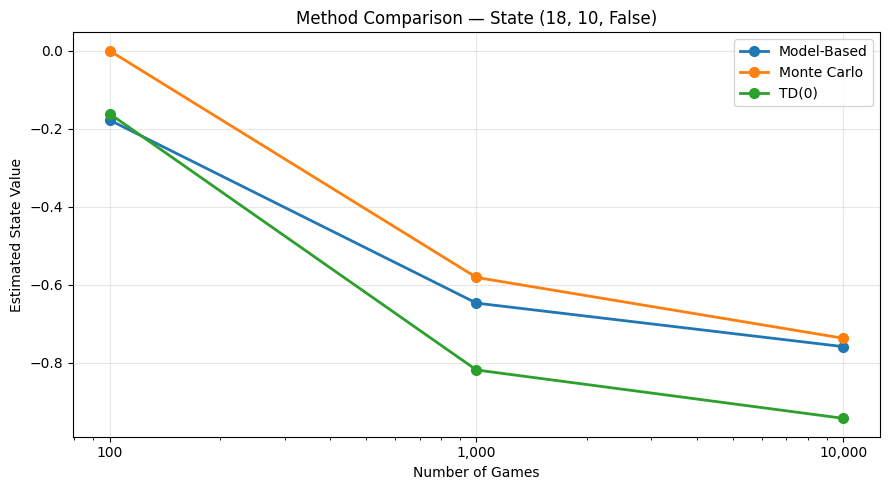

In [16]:
# D.5 — Corrected Method Comparison Plot

import pandas as pd
import matplotlib.pyplot as plt
import os

os.makedirs("outputs/comparison", exist_ok=True)

# State to compare
chosen_state = (18, 10, False)
seed = 11
checkpoints = [100, 1000, 10000]

# Results from the three methods
methods = {
    "Model-Based": all_results,
    "Monte Carlo": mc_results,
    "TD(0)": td_results
}

plot_rows = []

for method, results in methods.items():
    for n_games in checkpoints:

        df = results[(seed, n_games)]

        mask = (
            (df["Player sum"] == chosen_state[0]) &
            (df["Dealer card"] == chosen_state[1]) &
            (df["Usable ace"] == chosen_state[2])
        )

        selected = df.loc[mask]

        if not selected.empty:
            value = selected.iloc[0]["Value"]

            plot_rows.append({
                "Method": method,
                "Games": n_games,
                "Value": value
            })

plot_df = pd.DataFrame(plot_rows)

print("Comparison results:")
display(plot_df.round(4))

# Plot all three methods
plt.figure(figsize=(9, 5))

for method in methods:
    subset = plot_df[
        plot_df["Method"] == method
    ].sort_values("Games")

    valid = subset.dropna(subset=["Value"])

    if not valid.empty:
        plt.plot(
            valid["Games"],
            valid["Value"],
            marker="o",
            linewidth=2,
            markersize=7,
            label=method
        )

plt.xscale("log")
plt.xticks(
    checkpoints,
    ["100", "1,000", "10,000"]
)

plt.xlabel("Number of Games")
plt.ylabel("Estimated State Value")
plt.title(
    f"Method Comparison — State {chosen_state}"
)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "outputs/comparison/method_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

### Graph Conclusion

I compared three methods for state (18, 10, False).

All three methods produced negative estimates after 10,000 games.

Model-Based and Monte Carlo gave similar results.
TD(0) produced a more negative estimate.

The estimates changed as more games were observed.
This does not necessarily mean the policy became worse.

## D.6–D.7 — Q-learning with and without Exploration

I train two fresh Q-learning models for each seed, using epsilon = 0.2 and epsilon = 0.
I use 50,000 games per seed, alpha = 0.1 and gamma = 1.
The epsilon = 0.2 agent explores randomly 20% of the time.
The epsilon = 0 agent uses greedy actions, with seeded random tie-breaking.
I save Q-values, visit counts and policies for both experiments.

In [17]:
# D.6–D.7 — Q-learning experiments: epsilon 0.2 versus 0.0

import gymnasium as gym
import numpy as np
import pandas as pd
import os
from collections import defaultdict, Counter

alpha = 0.1
gamma = 1.0
num_games = 50000
seeds = [11, 22, 33]

def train_q_learning_fixed(seed, eps):

    env = gym.make(
        "Blackjack-v1",
        natural=False,
        sab=False
    )

    rng = np.random.default_rng(seed)
    Q = defaultdict(lambda: np.zeros(2))
    visits = Counter()
    records = []

    for game in range(1, num_games + 1):

        if game == 1:
            obs, _ = env.reset(seed=seed)
        else:
            obs, _ = env.reset()

        state = tuple(obs)
        final_reward = np.nan
        cutoff = False

        for step in range(1, 101):

            # Epsilon-greedy action selection
            if rng.random() < eps:
                action = int(rng.integers(0, 2))
            else:
                values = Q[state]
                best = np.flatnonzero(
                    values == np.max(values)
                )
                action = int(rng.choice(best))

            next_obs, reward, terminated, truncated, _ = (
                env.step(action)
            )

            if truncated or (step == 100 and not terminated):
                cutoff = True
                break

            next_state = tuple(next_obs)
            visits[(state, action)] += 1

            # Q-learning update
            if terminated:
                target = float(reward)
            else:
                target = (
                    float(reward)
                    + gamma * np.max(Q[next_state])
                )

            Q[state][action] += alpha * (
                target - Q[state][action]
            )

            if terminated:
                final_reward = float(reward)
                break

            state = next_state

        records.append({
            "Seed": seed,
            "Game": game,
            "Reward": final_reward,
            "Cutoff": cutoff
        })

    env.close()

    # Create Q-table
    q_rows = []

    for ace in [False, True]:
        for player_sum in range(4, 22):
            for dealer in range(1, 11):

                s = (player_sum, dealer, ace)
                stick = Q[s][0]
                hit = Q[s][1]

                stick_visits = visits[(s, 0)]
                hit_visits = visits[(s, 1)]

                if stick_visits + hit_visits == 0:
                    greedy = "Unvisited"
                elif hit > stick:
                    greedy = "Hit"
                elif stick > hit:
                    greedy = "Stick"
                else:
                    greedy = "Tie (random)"

                q_rows.append({
                    "Player sum": player_sum,
                    "Dealer card": dealer,
                    "Usable ace": ace,
                    "Q Stick": stick,
                    "Q Hit": hit,
                    "Stick visits": stick_visits,
                    "Hit visits": hit_visits,
                    "Greedy action": greedy
                })

    return pd.DataFrame(q_rows), pd.DataFrame(records)


# Train both experiments independently
all_experiments = {}
all_summaries = []

for eps in [0.2, 0.0]:

    folder = f"outputs/q-learning/epsilon_{eps}"
    os.makedirs(folder, exist_ok=True)

    results = {}
    summary_rows = []

    for seed in seeds:

        q_table, history = train_q_learning_fixed(
            seed, eps
        )

        results[seed] = (q_table, history)

        seed_folder = f"{folder}/seed_{seed}"
        os.makedirs(seed_folder, exist_ok=True)

        q_table.to_csv(
            f"{seed_folder}/q_values_and_counts.csv",
            index=False
        )

        history.to_csv(
            f"{seed_folder}/training_rewards.csv",
            index=False
        )

        # Save policy and action counts
        for ace, name in [
            (False, "no_usable_ace"),
            (True, "usable_ace")
        ]:
            subset = q_table[
                q_table["Usable ace"] == ace
            ]

            for column, filename in [
                ("Greedy action", "policy"),
                ("Hit visits", "hit_counts"),
                ("Stick visits", "stick_counts")
            ]:
                pivot = subset.pivot(
                    index="Player sum",
                    columns="Dealer card",
                    values=column
                )
                pivot.to_csv(
                    f"{seed_folder}/{filename}_{name}.csv"
                )

        completed = history["Reward"].dropna()

        summary_rows.append({
            "Seed": seed,
            "Games": len(history),
            "Wins": int((completed == 1).sum()),
            "Losses": int((completed == -1).sum()),
            "Draws": int((completed == 0).sum()),
            "Cutoffs": int(history["Cutoff"].sum()),
            "Mean reward": completed.mean()
        })

    summary = pd.DataFrame(summary_rows)

    summary.to_csv(
        f"{folder}/summary.csv",
        index=False
    )

    all_experiments[eps] = results
    all_summaries.append(
        summary.assign(Epsilon=eps)
    )

# Variables for the next graph
q_training_results_eps02 = all_experiments[0.2]
q_training_results_eps0 = all_experiments[0.0]

summary_q_eps02 = all_summaries[0].drop(
    columns="Epsilon"
)
summary_q_eps0 = all_summaries[1].drop(
    columns="Epsilon"
)

comparison_epsilon = pd.concat(
    all_summaries,
    ignore_index=True
)

print("Q-learning: Epsilon Comparison")
display(comparison_epsilon.round(4))

print("Both experiments completed successfully!")

Q-learning: Epsilon Comparison


,Seed,Games,Wins,Losses,Draws,Cutoffs,Mean reward,Epsilon
0,11,50000,19405,26725,3870,0,-0.1464,0.2
1,22,50000,19197,26792,4011,0,-0.1519,0.2
2,33,50000,19403,26757,3840,0,-0.1471,0.2
3,11,50000,20802,24699,4499,0,-0.0779,0.0
4,22,50000,20706,24661,4633,0,-0.0791,0.0
5,33,50000,20835,24563,4602,0,-0.0746,0.0


Both experiments completed successfully!


## D.6–D.7 — Q-learning Training Reward Curves

I compare Q-learning with epsilon = 0.2 and epsilon = 0.

I calculate the mean training reward for every 1,000 games.

I use three seeds: 11, 22, and 33.

I plot the learning curves to compare the training results.

These are training rewards, not frozen evaluation results.

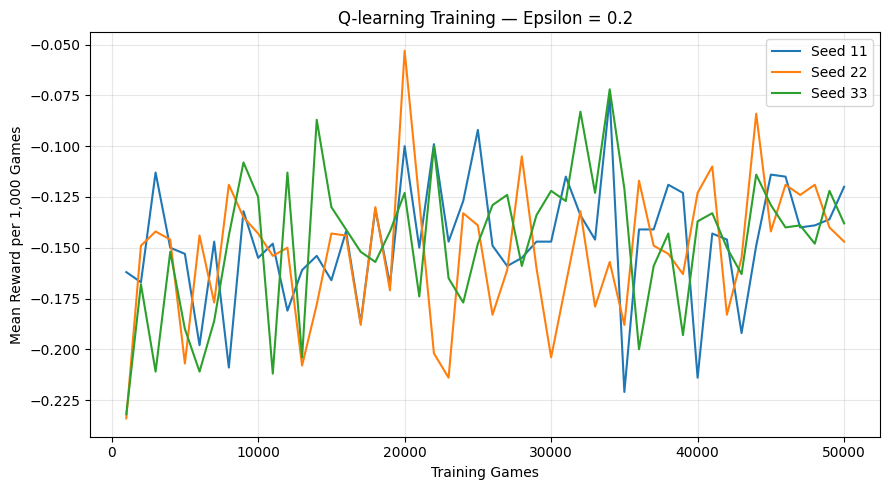

In [21]:
# Q-learning Training Curves — Epsilon = 0.2

import pandas as pd
import matplotlib.pyplot as plt
import os

epsilon_value = 0.2

folder = f"outputs/q-learning/epsilon_{epsilon_value}"
os.makedirs(folder, exist_ok=True)

plt.figure(figsize=(9, 5))

for seed in [11, 22, 33]:

    history = pd.read_csv(
        f"{folder}/seed_{seed}/training_rewards.csv"
    )

    history["Block"] = (history["Game"] - 1) // 1000 + 1

    mean_rewards = history.groupby("Block")["Reward"].mean()

    plt.plot(
        mean_rewards.index * 1000,
        mean_rewards.values,
        label=f"Seed {seed}"
    )

plt.title("Q-learning Training — Epsilon = 0.2")
plt.xlabel("Training Games")
plt.ylabel("Mean Reward per 1,000 Games")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{folder}/training_rewards.png",
    dpi=200
)
plt.show()

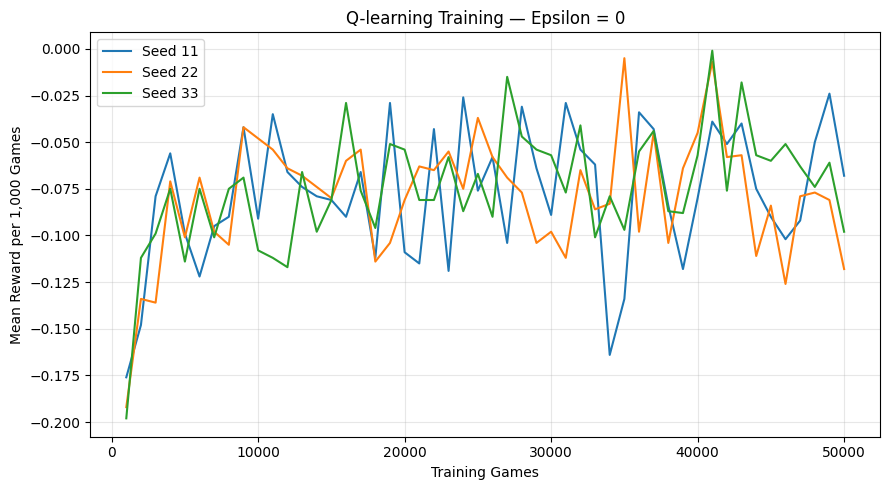

In [23]:
# Q-learning Training Curves — Epsilon = 0

epsilon_value = 0.0

folder = f"outputs/q-learning/epsilon_{epsilon_value}"
os.makedirs(folder, exist_ok=True)

plt.figure(figsize=(9, 5))

for seed in [11, 22, 33]:

    history = pd.read_csv(
        f"{folder}/seed_{seed}/training_rewards.csv"
    )

    history["Block"] = (history["Game"] - 1) // 1000 + 1

    mean_rewards = history.groupby("Block")["Reward"].mean()

    plt.plot(
        mean_rewards.index * 1000,
        mean_rewards.values,
        label=f"Seed {seed}"
    )

plt.title("Q-learning Training — Epsilon = 0")
plt.xlabel("Training Games")
plt.ylabel("Mean Reward per 1,000 Games")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{folder}/training_rewards.png",
    dpi=200
)
plt.show()

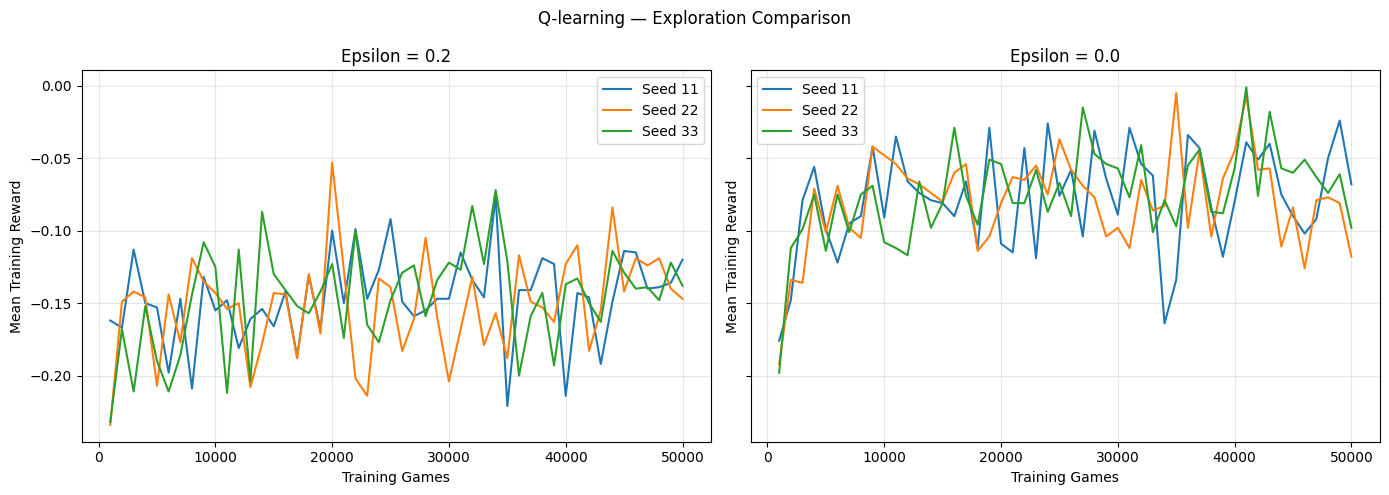

In [24]:
# Compare Epsilon = 0.2 and Epsilon = 0

fig, axes = plt.subplots(
    1, 2, figsize=(14, 5), sharey=True
)

for ax, eps in zip(axes, [0.2, 0.0]):

    for seed in [11, 22, 33]:

        history = pd.read_csv(
            f"outputs/q-learning/epsilon_{eps}/"
            f"seed_{seed}/training_rewards.csv"
        )

        history["Block"] = (
            (history["Game"] - 1) // 1000 + 1
        )

        mean_rewards = history.groupby(
            "Block"
        )["Reward"].mean()

        ax.plot(
            mean_rewards.index * 1000,
            mean_rewards.values,
            label=f"Seed {seed}"
        )

    ax.set_title(f"Epsilon = {eps}")
    ax.set_xlabel("Training Games")
    ax.set_ylabel("Mean Training Reward")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Q-learning — Exploration Comparison")
plt.tight_layout()

plt.savefig(
    "outputs/q-learning/epsilon_comparison.png",
    dpi=200
)

plt.show()

### Training Curves Conclusion

I compared Q-learning with epsilon = 0.2 and epsilon = 0.

With epsilon = 0.2, the agent explores random actions.

With epsilon = 0, the agent follows its current Q-values.

In my experiments, epsilon = 0 achieved a higher average training reward.

However, the separate evaluation showed that epsilon = 0.2 had a slightly better average result on new games.

This shows why training and evaluation should be compared separately.

## D.8 — Frozen Policy Evaluation

I evaluate the trained Q-learning policies on new Blackjack games.

I compare three policies:
- Fixed baseline
- Q-learning trained with epsilon = 0.2
- Q-learning trained with epsilon = 0

I use evaluation seeds 1011, 1022, and 1033.

Each policy plays 10,000 new games per seed.

During evaluation, I do not update Q-values or use epsilon exploration.

I record wins, losses, draws, cut-offs, and mean rewards.

In [18]:
# D.8 — Frozen Policy Evaluation

import gymnasium as gym
import numpy as np
import pandas as pd
import os

os.makedirs("outputs/q-learning/frozen-evaluation", exist_ok=True)

seed_pairs = {
    11: 1011,
    22: 1022,
    33: 1033
}

num_eval_games = 10000

def make_q_lookup(q_table):
    lookup = {}

    for _, row in q_table.iterrows():
        state = (
            int(row["Player sum"]),
            int(row["Dealer card"]),
            bool(row["Usable ace"])
        )

        lookup[state] = np.array([
            float(row["Q Stick"]),
            float(row["Q Hit"])
        ])

    return lookup


def evaluate_policy(train_seed, eval_seed, policy_name, q_table=None):

    env = gym.make(
        "Blackjack-v1",
        natural=False,
        sab=False
    )

    rng = np.random.default_rng(eval_seed)

    q_lookup = (
        make_q_lookup(q_table)
        if q_table is not None else None
    )

    records = []

    for game in range(1, num_eval_games + 1):

        if game == 1:
            obs, _ = env.reset(seed=eval_seed)
        else:
            obs, _ = env.reset()

        state = tuple(obs)
        reward_final = np.nan
        cutoff = False

        for step in range(1, 101):

            if policy_name == "Baseline":
                action = 1 if state[0] < 20 else 0

            else:
                # Greedy policy, no epsilon exploration
                values = q_lookup.get(
                    state, np.zeros(2)
                )

                best_actions = np.flatnonzero(
                    np.isclose(values, np.max(values))
                )

                # Random tie-breaking
                action = int(rng.choice(best_actions))

            next_obs, reward, terminated, truncated, _ = (
                env.step(action)
            )

            if terminated:
                reward_final = float(reward)
                break

            if truncated or step == 100:
                cutoff = True
                break

            state = tuple(next_obs)

        records.append({
            "Training seed": train_seed,
            "Evaluation seed": eval_seed,
            "Policy": policy_name,
            "Game": game,
            "Reward": reward_final,
            "Cutoff": cutoff
        })

    env.close()

    history = pd.DataFrame(records)
    completed = history["Reward"].dropna()

    summary = {
        "Training seed": train_seed,
        "Policy": policy_name,
        "Evaluation seed": eval_seed,
        "Wins": int((completed == 1).sum()),
        "Losses": int((completed == -1).sum()),
        "Draws": int((completed == 0).sum()),
        "Cut-offs": int(history["Cutoff"].sum()),
        "Mean reward": completed.mean()
    }

    return summary, history


eval_rows = []

for train_seed, eval_seed in seed_pairs.items():

    policies = {
        "Baseline": None,
        "Q-learning eps=0.2":
            q_training_results_eps02[train_seed][0],
        "Q-learning eps=0":
            q_training_results_eps0[train_seed][0]
    }

    for name, q_table in policies.items():

        summary, history = evaluate_policy(
            train_seed,
            eval_seed,
            name,
            q_table
        )

        eval_rows.append(summary)

        safe_name = name.replace(
            " ", "_"
        ).replace("=", "_")

        history.to_csv(
            "outputs/q-learning/frozen-evaluation/"
            f"{safe_name}_seed_{train_seed}.csv",
            index=False
        )

evaluation_df = pd.DataFrame(eval_rows)

evaluation_df.to_csv(
    "outputs/q-learning/frozen-evaluation/summary.csv",
    index=False
)

print("Frozen Policy Evaluation:")
display(evaluation_df.round(4))

print("Evaluation completed!")

Frozen Policy Evaluation:


,Training seed,Policy,Evaluation seed,Wins,Losses,Draws,Cut-offs,Mean reward
0,11,Baseline,1011,2962,6462,576,0,-0.3500
1,11,Q-learning eps=0.2,1011,4204,4894,902,0,-0.0690
2,11,Q-learning eps=0,1011,4107,4905,988,0,-0.0798
3,22,Baseline,1022,2935,6481,584,0,-0.3546
4,22,Q-learning eps=0.2,1022,4209,4847,944,0,-0.0638
5,22,Q-learning eps=0,1022,4145,4926,929,0,-0.0781
6,33,Baseline,1033,2950,6496,554,0,-0.3546
7,33,Q-learning eps=0.2,1033,4178,4941,881,0,-0.0763
8,33,Q-learning eps=0,1033,4227,4839,934,0,-0.0612


Evaluation completed!


### Evaluation Explanation

I tested the learned policies on new games.

I did not change the Q-tables during evaluation.

All policies used the same evaluation seeds.

I compared their mean rewards with the fixed baseline.

This helps me check whether Q-learning improved the playing strategy.

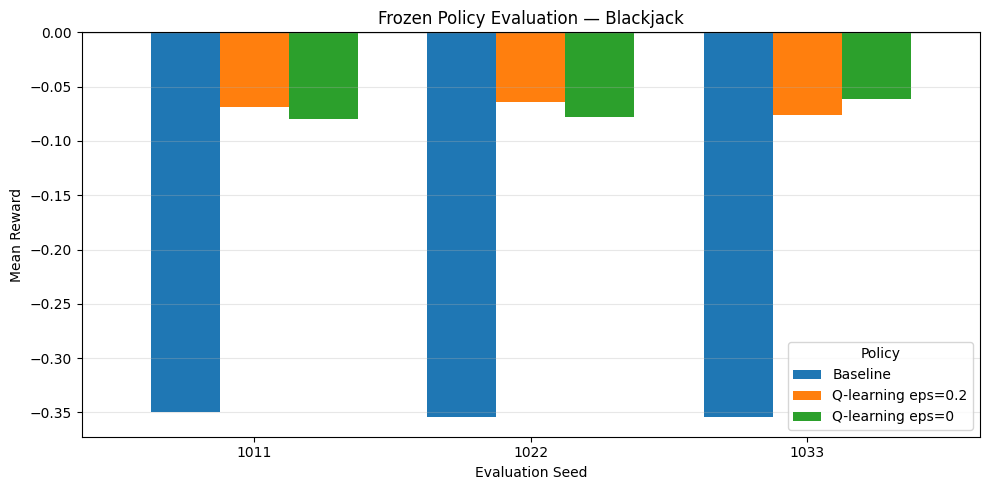

Final Evaluation Summary:


,Average reward,Standard deviation
Policy,,
Baseline,-0.3531,0.0027
Q-learning eps=0.2,-0.0697,0.0063
Q-learning eps=0,-0.0730,0.0103


In [19]:
# D.9 — Final Evaluation Comparison

import pandas as pd
import matplotlib.pyplot as plt
import os

folder = "outputs/q-learning/frozen-evaluation"
os.makedirs(folder, exist_ok=True)

policy_order = [
    "Baseline",
    "Q-learning eps=0.2",
    "Q-learning eps=0"
]

# Mean reward for each evaluation seed
plot_data = evaluation_df.pivot(
    index="Evaluation seed",
    columns="Policy",
    values="Mean reward"
)

plot_data = plot_data[policy_order]

# Create comparison chart
ax = plot_data.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.75
)

ax.set_title("Frozen Policy Evaluation — Blackjack")
ax.set_xlabel("Evaluation Seed")
ax.set_ylabel("Mean Reward")
ax.axhline(0, color="gray", linewidth=1)
ax.legend(title="Policy")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    f"{folder}/final_policy_comparison.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Average results across all three seeds
final_summary = (
    evaluation_df.groupby("Policy")[
        "Mean reward"
    ].agg(["mean", "std"])
    .reindex(policy_order)
)

final_summary.columns = [
    "Average reward", "Standard deviation"
]

print("Final Evaluation Summary:")
display(final_summary.round(4))

final_summary.to_csv(
    f"{folder}/final_summary.csv"
)

### Final Evaluation Conclusion

I evaluated the trained Q-learning policies on new Blackjack games.

The baseline had an average reward of -0.3531.

Q-learning with epsilon = 0.2 achieved -0.0697.
Q-learning with epsilon = 0 achieved -0.0730.

Both learned policies performed better than the baseline.

Epsilon = 0.2 had a slightly better average result, but epsilon = 0 performed better for one seed.

This shows that Q-learning improved the strategy in my experiments, but the results still depend on the seed and training data.

In [25]:
# Save Part C results and prepare HW7 outputs

import os
import shutil
import pandas as pd
import gymnasium as gym
from google.colab import files

folder = "outputs/paper-replay"
os.makedirs(folder, exist_ok=True)

# Check that previous Part C results exist
required = [
    "model_df", "value_df", "mc_df",
    "comparison_mc", "td_df", "q_df", "final_q"
]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(
        "Run the previous Part C cells first: "
        + ", ".join(missing)
    )

# Save complete results without rounding
tables = {
    "transition_model": model_df,
    "model_based_sweeps": value_df,
    "monte_carlo_returns": mc_df,
    "td0_updates": td_df,
    "q_learning_updates": q_df,
    "final_q_table": final_q
}

for name, table in tables.items():
    table.to_csv(f"{folder}/{name}.csv", index=False)

# Build one paper-versus-program comparison
rows = []
states_list = ["A", "B", "C", "D", "E"]

# Model-based comparison
for _, r in value_df.iterrows():
    sweep = int(r["Sweep"])
    for s in states_list:
        paper = 0.0 if sweep == 0 else (
            -1/3 if s == "A" else 0.0
        )
        value = float(r[s])
        rows.append([
            "Model-Based", s, f"Sweep {sweep}",
            paper, value, value - paper
        ])

# Monte Carlo comparison
for _, r in comparison_mc.iterrows():
    rows.append([
        "Monte Carlo", r["State"], "Pass 1",
        r["Paper"], r["MC Value"], r["Difference"]
    ])

# TD(0) comparison
for _, r in td_df.iterrows():
    rows.append([
        "TD(0)", r["State"],
        f"Pass {r['Pass']}, Game {r['Game']}, Step {r['Step']}",
        r["Paper"], r["New V"], r["Difference"]
    ])

# Q-learning comparison
for _, r in q_df.iterrows():
    rows.append([
        "Q-learning", f"{r['State']} / {r['Action']}",
        f"Pass {r['Pass']}, Game {r['Game']}, Step {r['Step']}",
        r["Paper"], r["New Q"], r["Difference"]
    ])

comparison = pd.DataFrame(rows, columns=[
    "Method", "State / Action", "Sweep / Pass / Update",
    "Paper result", "Program result", "Difference"
])

comparison.to_csv(
    f"{folder}/paper_vs_program.csv",
    index=False
)

print("Paper replay saved!")
print("Comparison rows:", len(comparison))
print("Maximum difference:",
      comparison["Difference"].abs().max())

# Record dependency versions
with open("outputs/dependency_versions.txt", "w") as f:
    f.write(f"Python: {__import__('sys').version.split()[0]}\n")
    f.write(f"Pandas: {pd.__version__}\n")
    f.write(f"Gymnasium: {gym.__version__}\n")

# Create one ZIP containing the entire outputs folder
shutil.make_archive(
    "hw7_outputs", "zip",
    root_dir=".", base_dir="outputs"
)

print("Created hw7_outputs.zip")
files.download("hw7_outputs.zip")

Paper replay saved!
Comparison rows: 52
Maximum difference: 2.7755575615628914e-17
Created hw7_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>